# 05 — Từ địa điểm tới Home / Office / POI

**Input:** toàn bộ assignments và địa điểm của hai phương pháp trong NB04. Giữ nguyên clusters, không clustering lại và không lấy mẫu. Thống kê đủ mọi user, kể cả người không có stay hoặc chỉ có noise.

Thứ tự: **tính thời gian ghé → xem bằng chứng → chấm điểm → chọn nhãn hoặc `unknown`**. Cùng một nơi có thể là cả Home và Office. POI chỉ là địa điểm thường ghé khác, chưa biết đó là quán ăn, phòng gym hay nơi gì.

Đây là suy luận theo rule, không train classifier và không có nhãn độc lập để báo accuracy. Ngưỡng/weights đang là baseline. Notebook không triển khai API.

## 1. Đọc đúng kết quả phase 4

Chọn kernel **Python (GeoLife)**, rồi **Restart Kernel and Run All** để nạp phiên bản core vừa cập nhật. Kiểm tra audit NB04 đã hoàn thành, các file nguồn chưa bị đổi, và toàn bộ stays/địa điểm vẫn cân bằng với NB03.

Ngoài stays, phần coverage cần đọc **toàn bộ GPS sạch** theo luồng một lần: người không có stay vẫn có thể có GPS khi đang di chuyển. Không dùng riêng các stays làm mẫu số cho “ngày đã quan sát”.

In [1]:
from pathlib import Path
from dataclasses import replace
import hashlib
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src' / 'geolife_inference').is_dir())
assert Path(sys.prefix).resolve() == (ROOT / '.venv').resolve(), 'Hãy chọn kernel Python (GeoLife).'

from geolife_inference.config import Config
from geolife_inference.features import (cluster_features, observation_coverage,
                                        stream_observation_coverage, temporal_summary)
from geolife_inference.inference import (AMBIGUITY_MARGIN, EVIDENCE_WEIGHTS,
                                         infer_locations, role_candidates)

SOURCE = ROOT / 'artifacts' / 'locations'
PREP = ROOT / 'artifacts' / 'preprocessing'
STAYS = ROOT / 'artifacts' / 'stays'
OUT = ROOT / 'artifacts' / 'inference'
OUT.mkdir(parents=True, exist_ok=True)
CLEANED = PREP / 'cleaned_points.csv.gz'
SMALL_INPUTS = [SOURCE / 'audit.json', SOURCE / 'stay_assignments.csv', SOURCE / 'locations.csv',
                SOURCE / 'per_user.csv', STAYS / 'audit.json', STAYS / 'per_user.csv', PREP / 'audit.json']
assert CLEANED.is_file() and all(path.is_file() for path in SMALL_INPUTS), 'Chạy xong NB02–04 trước.'

def input_fingerprints():
    stat = CLEANED.stat()
    return {'tables': {str(path.relative_to(ROOT)): hashlib.sha256(path.read_bytes()).hexdigest()
                       for path in SMALL_INPUTS},
            'cleaned_gps': {'bytes': stat.st_size, 'mtime_ns': stat.st_mtime_ns}}

INPUT_FINGERPRINTS = input_fingerprints()
source_audit = json.loads((SOURCE / 'audit.json').read_text(encoding='utf-8'))
prep_audit = json.loads((PREP / 'audit.json').read_text(encoding='utf-8'))
stay_audit = json.loads((STAYS / 'audit.json').read_text(encoding='utf-8'))
for audit in [source_audit, prep_audit, stay_audit]:
    assert audit['status'] == 'completed' and audit['scope'] == 'full_dataset'
for relative, digest in source_audit['input_fingerprints'].items():
    assert hashlib.sha256((ROOT / relative.replace('\\', '/')).read_bytes()).hexdigest() == digest, 'Input NB04 đã đổi.'
for relative, snapshot in stay_audit['input'].items():
    stat = (ROOT / relative.replace('\\', '/')).stat()
    assert stat.st_size == snapshot['bytes'] and stat.st_mtime_ns == snapshot['mtime_ns'], 'Input NB03 đã đổi.'

In [2]:
assignments = pd.read_csv(SOURCE / 'stay_assignments.csv', dtype={
    'stay_id': 'string', 'user_id': 'string', 'trajectory_id': 'string',
    'latitude': 'float64', 'longitude': 'float64', 'duration_minutes': 'float64', 'point_count': 'int64'})
for col in ['start_time', 'end_time']:
    assignments[col] = pd.to_datetime(assignments[col], utc=True, errors='raise')
saved_locations = pd.read_csv(SOURCE / 'locations.csv', dtype={'user_id': 'string'})
users = pd.read_csv(STAYS / 'per_user.csv', dtype={'user_id': 'string'}).set_index('user_id')
expected = pd.DataFrame(prep_audit['per_user']).set_index('user_id')
METHODS = list(source_audit['methods'])
assert set(METHODS) == {'heuristic-v1', 'dbscan-v1'}
assert users.index.is_unique and set(users.index) == set(prep_audit['expected_users'])
assert len(users) == source_audit['input_users'] == prep_audit['completed_user_count']
assert len(assignments) == source_audit['input_stays'] == stay_audit['stay_events']
assert assignments['stay_id'].is_unique and assignments['user_id'].isin(users.index).all()
assert assignments.groupby('user_id').size().reindex(users.index, fill_value=0).eq(users['stay_count']).all()
assert np.isclose(assignments['duration_minutes'].sum(), source_audit['input_stay_minutes'])
assert not saved_locations.duplicated(['method', 'user_id', 'cluster_id']).any()
for row in source_audit['comparison']:
    assert len(saved_locations.loc[saved_locations['method'].eq(row['method'])]) == row['locations']
print(f"Input: {len(users)} users / {len(assignments):,} stays / {len(saved_locations):,} địa điểm cộng hai phương pháp.")

Input: 182 users / 10,339 stays / 4,129 địa điểm cộng hai phương pháp.


## 2. Rule và múi giờ

Dùng **Asia/Shanghai (UTC+8)** để đọc thói quen trong GeoLife, không dùng giờ của máy ở Việt Nam. Giờ lưu trong CSV vẫn là UTC. Travel sang múi giờ khác và người làm ca đêm có thể khiến giả định sai.

| Vai trò | Thời gian xét | Điều kiện tối thiểu ban đầu |
|---|---|---|
| Home | 22h–6h, mọi ngày | ≥ 3 ngày có dừng ban đêm và ≥ 60 phút ban đêm |
| Office | 9h–18h, thứ Hai–thứ Sáu | ≥ 3 ngày, ≥ 60 phút trong khung giờ này và ≥ 2 tuần ISO |
| POI | Bất kỳ giờ nào | Cluster còn lại có ≥ 3 ngày ghé; tối đa 10 nơi/user/phương pháp |

Thời lượng được chia theo **phần giao thực tế với khung giờ**. Ví dụ 21:50–22:20 chỉ góp 20 phút cho Home. Stay kết thúc đúng 00:00 không góp thời lượng cho ngày mới. Không cộng gap giữa hai lần ghé. Ngày lễ chưa được mô hình hóa.

In [3]:
grouping = source_audit['grouping_config']
CONFIG = Config(
    timezone=grouping['timezone'], eps_m=grouping['eps_m'], min_samples=grouping['min_samples'],
    max_gap_minutes=prep_audit['max_gap_minutes'],
    distance_m=stay_audit['config']['distance_m'], min_stay_minutes=stay_audit['config']['min_stay_minutes'],
    night_start_hour=22, night_end_hour=6, work_start_hour=9, work_end_hour=18,
    min_role_days=3, min_office_weeks=2, min_role_dwell_minutes=60,
    min_evidence_score=.5, min_candidate_share=.5, min_poi_days=3, max_pois=10,
)
assert CONFIG.max_gap_minutes == stay_audit['config']['max_gap_minutes']
assert CONFIG.timezone == grouping['timezone'], 'Giữ timezone NB04 để so ngày ghé; muốn đổi cần review lại từ NB04.'

def temporal_config(config):
    return {k: config.to_dict()[k] for k in ['timezone', 'max_gap_minutes', 'night_start_hour',
            'night_end_hour', 'work_start_hour', 'work_end_hour']}

BASE_TEMPORAL_CONFIG = temporal_config(CONFIG)
display(pd.Series({k: CONFIG.to_dict()[k] for k in [
    'timezone', 'night_start_hour', 'night_end_hour', 'work_start_hour', 'work_end_hour',
    'min_role_days', 'min_office_weeks', 'min_role_dwell_minutes',
    'min_evidence_score', 'min_candidate_share', 'min_poi_days', 'max_pois']}, name='Rule baseline'))

timezone                  Asia/Shanghai
night_start_hour                     22
night_end_hour                        6
work_start_hour                       9
work_end_hour                        18
min_role_days                         3
min_office_weeks                      2
min_role_dwell_minutes               60
min_evidence_score                  0.5
min_candidate_share                 0.5
min_poi_days                          3
max_pois                             10
Name: Rule baseline, dtype: object

## 3. Tính thời gian có GPS quan sát được — toàn dataset

Hai GPS points liên tiếp trong **cùng trajectory và observation_segment**, cách nhau > 0 và ≤ 5 phút, tạo một khoảng quan sát. Các khoảng nối tiếp được nén thành đoạn trước khi union; không nối qua conflict chưa giải quyết hoặc gap lớn. Nếu hai file chồng thời gian thì chỉ đếm phần đó một lần.

- `observed_days`: số ngày có GPS point, kể cả ngày không có stay.
- `night_observed_days`, `work_observed_days`: số ngày có **thời lượng quan sát > 0** trong khung Home/Office.
- `observed_minutes`: tổng phút trong các khoảng quan sát, gồm cả khi di chuyển; không phải toàn bộ thời gian của người đó.

Đọc mọi GPS point nhưng chỉ giữ một trajectory và các khoảng đã nén của một user trong RAM. Sau lần đầu, cache chỉ được dùng lại khi input và cấu hình khung giờ khớp; đổi rule chấm điểm không cần đọc lại GPS.

In [4]:
run_audit = {'status': 'running', 'scope': 'full_dataset', 'policy': 'temporal-evidence-v1',
             'input_fingerprints': INPUT_FINGERPRINTS, 'config': CONFIG.to_dict(),
             'methods': METHODS, 'score_weights': EVIDENCE_WEIGHTS,
             'ambiguity_margin': AMBIGUITY_MARGIN}

def write_json(path, value):
    partial = path.with_suffix(path.suffix + '.partial')
    partial.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
    partial.replace(path)

def write_audit():
    write_json(OUT / 'audit.json', run_audit)

def get_full_coverage():
    cache_path, meta_path = OUT / 'coverage.csv', OUT / 'coverage_audit.json'
    cache_key = {'input_fingerprints': INPUT_FINGERPRINTS, 'temporal_config': BASE_TEMPORAL_CONFIG,
                 'policy': 'gps-pair-union-segment-aware-v2'}
    metadata = json.loads(meta_path.read_text(encoding='utf-8')) if meta_path.is_file() else {}
    if cache_path.is_file() and metadata.get('status') == 'completed' and metadata.get('key') == cache_key:
        digest = hashlib.sha256(cache_path.read_bytes()).hexdigest()
        assert digest == metadata['coverage_sha256'], 'Cache coverage đã đổi; xóa cache hoặc chạy lại phần này.'
        coverage = pd.read_csv(cache_path, dtype={'user_id': 'string'}).set_index('user_id')
        print('Dùng cache coverage đã khớp toàn bộ input và khung giờ.')
    else:
        rows = []
        for row in stream_observation_coverage(CLEANED, CONFIG):
            rows.append(row)
            if len(rows) % 20 == 0:
                print(f"Đã đọc coverage {len(rows)} users / {sum(r['processed_points'] for r in rows):,} points")
        # User không còn point sau cleaning vẫn có một hàng 0 nếu audit NB02 xác nhận như vậy.
        seen = {row['user_id'] for row in rows}
        empty = pd.DataFrame(columns=['user_id', 'trajectory_id', 'timestamp'])
        for user in users.index:
            if user not in seen:
                assert expected.loc[user, 'output_points'] == 0, f'Thiếu GPS của user {user}'
                rows.append(dict(user_id=user, processed_points=0, processed_trajectories=0,
                                 **observation_coverage(empty, CONFIG)))
        coverage = pd.DataFrame(rows).set_index('user_id')
    assert coverage.index.is_unique and set(coverage.index) == set(users.index)
    coverage = coverage.reindex(users.index)
    assert coverage['processed_points'].eq(expected['output_points']).all(), 'Số GPS points từng user không khớp NB02.'
    assert coverage['processed_trajectories'].eq(expected['after_trajectories']).all(), 'Số trajectories từng user không khớp NB02.'
    assert int(coverage['processed_points'].sum()) == prep_audit['totals']['output_points']
    assert int(coverage['processed_trajectories'].sum()) == source_audit['source_processed_trajectories']
    assert input_fingerprints() == INPUT_FINGERPRINTS, 'Input đổi khi tính coverage; chạy lại từ phần 1.'
    partial = cache_path.with_suffix('.csv.partial')
    coverage.to_csv(partial)
    partial.replace(cache_path)
    write_json(meta_path, {'status': 'completed', 'scope': 'full_dataset', 'key': cache_key,
                          'processed_users': len(coverage),
                          'processed_points': int(coverage['processed_points'].sum()),
                          'coverage_sha256': hashlib.sha256(cache_path.read_bytes()).hexdigest()})
    return coverage

In [5]:
write_audit()
try:
    coverage = get_full_coverage()
except Exception as error:
    run_audit.update(status='failed', error=str(error))
    write_audit()
    raise
coverage_by_user = {str(u): {k: None if pd.isna(v) else v for k, v in row.items()}
                    for u, row in coverage.to_dict('index').items()}
print(f"Đủ {len(coverage)} users / {int(coverage['processed_points'].sum()):,} cleaned GPS points.")
display(coverage)

Đã đọc coverage 20 users / 4,991,451 points
Đã đọc coverage 40 users / 9,201,178 points
Đã đọc coverage 60 users / 11,573,677 points
Đã đọc coverage 80 users / 14,009,814 points
Đã đọc coverage 100 users / 15,682,402 points
Đã đọc coverage 120 users / 16,194,080 points
Đã đọc coverage 140 users / 18,399,350 points
Đã đọc coverage 160 users / 21,942,166 points
Đã đọc coverage 180 users / 24,129,919 points
Đủ 182 users / 24,177,772 cleaned GPS points.


,processed_points,processed_trajectories,observed_minutes,observed_days,calendar_span_days,observed_day_fraction,observed_time_fraction,night_observed_days,work_observed_days,first_timestamp,last_timestamp
user_id,,,,,,,,,,,
000,173870,171,15131.783333,123,256,0.480469,0.041176,67,84,2008-10-23T02:53:04+00:00,2009-07-05T07:45:15+00:00
001,108607,71,6948.266667,44,54,0.814815,0.091427,23,16,2008-10-23T05:53:05+00:00,2008-12-15T00:31:18+00:00
002,248214,175,16439.466667,118,151,0.781457,0.076205,39,53,2008-10-23T12:45:23+00:00,2009-03-22T08:13:37+00:00
003,485226,322,42290.766667,237,255,0.929412,0.115364,143,164,2008-10-23T17:58:54+00:00,2009-07-05T07:45:15+00:00
004,439397,395,37605.600000,260,279,0.931900,0.093766,185,182,2008-10-23T17:58:52+00:00,2009-07-29T06:16:11+00:00
...,...,...,...,...,...,...,...,...,...,...,...
177,2955,1,175.983333,1,1,1.000000,0.796065,1,0,2009-09-19T17:11:22+00:00,2009-09-19T20:52:26+00:00
178,84,1,7.000000,1,1,1.000000,1.000000,1,0,2010-03-12T17:26:08+00:00,2010-03-12T17:33:08+00:00
179,155312,71,6471.900000,46,102,0.450980,0.044570,13,22,2008-08-20T12:09:04+00:00,2008-11-29T08:16:00+00:00


## 4. Tính bằng chứng thời gian cho mọi cluster

Tính lại phần giao ban đêm/giờ làm việc từ toàn bộ stays của mỗi cluster. Kiểm tra số stays, số ngày và tổng dwell vẫn khớp NB04. Các cột mới quan trọng:

| Cột | Ý nghĩa |
|---|---|
| `night_dwell_minutes`, `night_visit_days` | Phút/ngày dừng trong khung Home |
| `weekday_daytime_dwell_minutes`, `weekday_daytime_visit_days`, `weekday_daytime_weeks` | Phút/ngày/tuần trong khung Office |
| `observation_coverage` | Số ngày ghé cluster / số ngày user có GPS point; không phải xác suất đúng |

Noise không thành ứng viên Home/Office/POI, nhưng thời lượng của noise vẫn được thống kê. **Dwell trong các cluster + dwell của noise phải bằng dwell trong toàn bộ stays** ở mỗi khung giờ.

In [6]:
FEATURE_COLUMNS = ['method', 'user_id', 'cluster_id', 'latitude', 'longitude', 'stay_event_count',
    'total_dwell_minutes', 'night_dwell_minutes', 'weekday_dwell_minutes', 'weekday_daytime_dwell_minutes',
    'weekend_dwell_minutes', 'visit_count', 'unique_visit_days', 'distinct_weeks', 'night_visit_days',
    'weekday_daytime_visit_days', 'weekday_daytime_weeks', 'mean_visit_duration',
    'radius_max_m', 'radius_p95_m', 'observation_coverage']
features_by_key, diagnostics_by_key = {}, {}
feature_rows, diagnostic_rows = [], []
try:
    for method in METHODS:
        for user in users.index:
            frame = assignments.loc[assignments['user_id'].eq(user)].copy()
            frame['cluster_id'] = frame[method + '_cluster_id'].astype('int64')
            features = cluster_features(frame, coverage_by_user[str(user)], CONFIG)
            assert all(f['night_visit_days'] <= coverage_by_user[str(user)]['night_observed_days']
                       and f['weekday_daytime_visit_days'] <= coverage_by_user[str(user)]['work_observed_days']
                       for f in features), 'Ngày ghé vượt số ngày có GPS quan sát.'
            features_by_key[(method, str(user))] = features
            feature_rows.extend(dict(method=method, **feature) for feature in features)
            noise_frame = frame.loc[frame['cluster_id'].eq(-1)]
            noise = temporal_summary(zip(noise_frame['start_time'], noise_frame['end_time']), CONFIG)
            all_stays = temporal_summary(zip(frame['start_time'], frame['end_time']), CONFIG)
            for column in ['total_dwell_minutes', 'night_dwell_minutes', 'weekday_daytime_dwell_minutes']:
                assert np.isclose(sum(f[column] for f in features) + noise[column], all_stays[column])
            row = dict(method=method, user_id=str(user), stay_count=len(frame), noise_stays=len(noise_frame),
                       noise_fraction=len(noise_frame) / len(frame) if len(frame) else 0.0,
                       locations=len(features), noise_night_minutes=noise['night_dwell_minutes'],
                       noise_work_minutes=noise['weekday_daytime_dwell_minutes'],
                       all_stay_night_minutes=all_stays['night_dwell_minutes'],
                       all_stay_work_minutes=all_stays['weekday_daytime_dwell_minutes'])
            diagnostics_by_key[(method, str(user))] = row
            diagnostic_rows.append(row)
    location_features = pd.DataFrame(feature_rows, columns=FEATURE_COLUMNS)
    user_diagnostics = pd.DataFrame(diagnostic_rows)
    keys = ['method', 'user_id', 'cluster_id']
    assert set(map(tuple, location_features[keys].to_numpy())) == set(map(tuple, saved_locations[keys].to_numpy()))
    check = location_features.merge(saved_locations, on=keys, suffixes=('_new', '_nb04'), validate='one_to_one')
    for column in ['stay_event_count', 'visit_count', 'unique_visit_days', 'total_dwell_minutes', 'radius_max_m']:
        assert np.allclose(check[column + '_new'].to_numpy(dtype=float), check[column + '_nb04'].to_numpy(dtype=float))
except Exception as error:
    run_audit.update(status='failed', error=str(error))
    write_audit()
    raise
display(location_features)

,method,user_id,cluster_id,latitude,longitude,stay_event_count,total_dwell_minutes,night_dwell_minutes,weekday_dwell_minutes,weekday_daytime_dwell_minutes,...,visit_count,unique_visit_days,distinct_weeks,night_visit_days,weekday_daytime_visit_days,weekday_daytime_weeks,mean_visit_duration,radius_max_m,radius_p95_m,observation_coverage
0,heuristic-v1,000,0,40.008971,116.321503,2,22.266667,0.000000,22.266667,22.266667,...,2,2,2,0,2,2,11.133333,6.060469e+00,6.060469e+00,0.016260
1,heuristic-v1,000,1,40.011513,116.296895,3,54.500000,0.000000,54.500000,21.233333,...,3,3,3,0,2,2,18.166667,1.578970e+01,1.496705e+01,0.024390
2,heuristic-v1,000,2,40.006912,116.295890,1,16.250000,0.000000,16.250000,16.250000,...,1,1,1,0,1,1,16.250000,0.000000e+00,0.000000e+00,0.008130
3,heuristic-v1,000,3,40.006558,116.297088,1,14.833333,0.000000,14.833333,14.833333,...,1,1,1,0,1,1,14.833333,2.167159e-09,2.167159e-09,0.008130
4,heuristic-v1,000,4,40.009695,116.315136,27,512.083333,261.283333,132.266667,34.600000,...,27,7,3,3,3,2,18.966049,4.554905e+01,3.195969e+01,0.056911
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4124,dbscan-v1,174,0,39.986092,116.329029,4,58.250000,0.000000,58.250000,0.000000,...,4,1,1,0,0,0,14.562500,1.516635e+01,1.503067e+01,0.014706
4125,dbscan-v1,179,0,40.088264,116.305904,23,383.133333,198.883333,158.000000,16.866667,...,23,9,6,4,1,1,16.657971,1.485567e+02,1.340341e+02,0.195652
4126,dbscan-v1,179,1,40.007983,116.319353,20,316.700000,151.266667,262.366667,42.000000,...,20,7,6,3,1,1,15.835000,9.318210e+01,5.900739e+01,0.152174
4127,dbscan-v1,179,2,39.999541,116.327784,5,189.566667,41.066667,189.566667,105.016667,...,5,2,2,1,1,1,37.913333,2.173941e+01,2.159362e+01,0.043478


## 5. Chấm điểm, so đối thủ và trả `unknown`

Với mỗi vai trò, gọi **N** là số ngày ghé đúng khung giờ, **D** là số phút dừng trong khung đó,
**O** là số ngày có GPS quan sát trong khung đó, **T** là tổng phút GPS quan sát, **S** là phần dwell của cluster so với tổng dwell đúng khung ở **các cluster không phải noise**.

| Thành phần | Cách tính, chặn tối đa 1 | Trọng số |
|---|---|---:|
| Lặp lại theo ngày | N / 5 | 0,30 |
| Thời lượng | D / 600 phút | 0,25 |
| Xuất hiện trong ngày được quan sát | N / max(O, 1) | 0,20 |
| Lượng dữ liệu quan sát | T / 1.440 phút | 0,15 |
| Nổi bật so với cluster khác | S | 0,10 |

Điểm = tổng năm phần đã nhân trọng số. **Các weights và mốc 5 ngày/600 phút/1.440 phút do project đặt, chưa được học hoặc hiệu chuẩn.** Đây không phải xác suất. Thành phần lượng dữ liệu giống nhau cho các cluster của cùng user; nó giúp kiểm tra mức bằng chứng chứ không phân biệt vị trí.

Chọn ứng viên đủ điều kiện ngày/phút/tuần có điểm cao nhất. Chỉ gán nhãn nếu điểm ≥ 0,5, share ≥ 0,5 và hơn mọi đối thủ ít nhất 0,05 điểm (kể cả đối thủ chưa đủ ngày). Nếu không thì `unknown` với lý do `insufficient_evidence`, `low_evidence_score` hoặc `ambiguous_candidates`.

**Cần đọc noise cùng kết quả:** share loại noise khỏi mẫu số nên có thể trông cao dù nhiều dwell đang là noise. Bảng candidates có thêm `share_including_noise` để đối chiếu; cột này là diagnostic, chưa thay rule baseline.

Home và Office xét độc lập. POIs là các cluster còn lại có ≥ 3 ngày ghé, xếp số ngày rồi dwell, tối đa 10; không tự gọi loại hình doanh nghiệp. Khi Home còn unknown, một cluster có bằng chứng Home vẫn có thể nằm trong POIs vì chưa được chọn làm Home.

In [7]:
DECISION_COLUMNS = ['method', 'user_id', 'role', 'status', 'reason', 'input_context',
    'cluster_id', 'latitude', 'longitude', 'evidence_score', 'role_dwell_minutes', 'role_visit_days',
    'top_ranked_cluster_id', 'top_ranked_score']
SCORE_COLUMNS = ['method', 'user_id', 'role', 'rank', 'cluster_id', 'latitude', 'longitude',
    'evidence_score', 'role_dwell_minutes', 'role_visit_days', 'relative_share', 'eligible',
    'selected', 'eligibility_failures', 'share_including_noise',
    *['component_' + k for k in EVIDENCE_WEIGHTS], *['weighted_' + k for k in EVIDENCE_WEIGHTS]]
POI_COLUMNS = ['method', 'user_id', 'cluster_id', 'latitude', 'longitude', 'unique_visit_days',
               'visit_count', 'total_dwell_minutes']

def infer_all(config):
    assert temporal_config(config) == BASE_TEMPORAL_CONFIG, 'Khung giờ đã đổi; tính lại coverage/features từ phần 3.'
    decisions, scores, pois, results = [], [], [], []
    for method in METHODS:
        for user in users.index:
            user = str(user)
            features = features_by_key[(method, user)]
            cov = coverage_by_user[user]
            diagnostic = diagnostics_by_key[(method, user)]
            prediction = infer_locations(features, cov, config)
            results.append(dict(method=method, user_id=user, **prediction))
            lookup = {f['cluster_id']: f for f in features}
            for role in ['home', 'office']:
                decision = prediction[role]
                candidate = decision['candidate']
                ranked = role_candidates(features, cov, config, role)
                top = ranked[0] if ranked else None
                context = ('no_stays' if not diagnostic['stay_count'] else
                           'no_non_noise_cluster' if not features else 'has_clusters')
                decisions.append(dict(method=method, user_id=user, role=role,
                    status=decision['status'], reason=decision['reason'], input_context=context,
                    cluster_id=candidate['cluster_id'] if candidate else None,
                    latitude=candidate['latitude'] if candidate else None,
                    longitude=candidate['longitude'] if candidate else None,
                    evidence_score=candidate['evidence_score'] if candidate else None,
                    role_dwell_minutes=candidate['role_dwell_minutes'] if candidate else None,
                    role_visit_days=candidate['role_visit_days'] if candidate else None,
                    top_ranked_cluster_id=top['cluster_id'] if top else None,
                    top_ranked_score=top['evidence_score'] if top else None))
                for rank, item in enumerate(ranked, 1):
                    failures = []
                    if item['role_visit_days'] < config.min_role_days: failures.append('too_few_role_days')
                    if item['role_dwell_minutes'] < config.min_role_dwell_minutes: failures.append('too_little_role_dwell')
                    if role == 'office' and lookup[item['cluster_id']]['weekday_daytime_weeks'] < config.min_office_weeks:
                        failures.append('too_few_work_weeks')
                    denominator = diagnostic['all_stay_night_minutes' if role == 'home' else 'all_stay_work_minutes']
                    scores.append(dict(method=method, user_id=user, role=role, rank=rank,
                        **{k: v for k, v in item.items() if k != 'evidence_components'},
                        selected=bool(candidate and candidate['cluster_id'] == item['cluster_id']),
                        eligibility_failures=';'.join(failures),
                        share_including_noise=item['role_dwell_minutes'] / denominator if denominator else 0.0,
                        **{'component_' + k: v for k, v in item['evidence_components'].items()},
                        **{'weighted_' + k: v * EVIDENCE_WEIGHTS[k] for k, v in item['evidence_components'].items()}))
            pois.extend(dict(method=method, **{k: f[k] for k in POI_COLUMNS if k not in ['method']})
                        for f in prediction['pois'])
    decision_table = pd.DataFrame(decisions, columns=DECISION_COLUMNS)
    for col in ['cluster_id', 'top_ranked_cluster_id']:
        decision_table[col] = pd.array(decision_table[col], dtype='Int64')
    return (decision_table, pd.DataFrame(scores, columns=SCORE_COLUMNS),
            pd.DataFrame(pois, columns=POI_COLUMNS), results)

In [8]:
try:
    decisions, candidate_scores, pois, predictions = infer_all(CONFIG)
    assert len(decisions) == len(users) * len(METHODS) * 2
    assert not decisions.duplicated(['method', 'user_id', 'role']).any()
    assert len(predictions) == len(users) * len(METHODS)
    if not candidate_scores.empty:
        assert candidate_scores['evidence_score'].between(0, 1).all()
        assert np.allclose(candidate_scores.filter(like='weighted_').sum(axis=1), candidate_scores['evidence_score'])
        assert candidate_scores.groupby(['method', 'user_id', 'role'])['selected'].sum().le(1).all()
    selected = decisions.loc[decisions['status'].eq('predicted')]
    assert selected['cluster_id'].notna().all() and selected['evidence_score'].ge(CONFIG.min_evidence_score).all()
    assert decisions.loc[decisions['status'].eq('unknown'), 'cluster_id'].isna().all()
    assert len(candidate_scores) == len(location_features) * 2
except Exception as error:
    run_audit.update(status='failed', error=str(error))
    write_audit()
    raise
display(decisions)
display(pois)

,method,user_id,role,status,reason,input_context,cluster_id,latitude,longitude,evidence_score,role_dwell_minutes,role_visit_days,top_ranked_cluster_id,top_ranked_score
0,heuristic-v1,000,home,predicted,sufficient_heuristic_evidence,has_clusters,4,40.009695,116.315136,0.509805,261.283333,3.0,4,0.509805
1,heuristic-v1,000,office,unknown,insufficient_evidence,has_clusters,<NA>,NaN,NaN,NaN,NaN,NaN,6,0.437009
2,heuristic-v1,001,home,predicted,sufficient_heuristic_evidence,has_clusters,0,40.013804,116.306487,0.603415,374.416667,3.0,0,0.603415
3,heuristic-v1,001,office,unknown,insufficient_evidence,has_clusters,<NA>,NaN,NaN,NaN,NaN,NaN,6,0.331479
4,heuristic-v1,002,home,predicted,sufficient_heuristic_evidence,has_clusters,1,39.926223,116.337491,0.873107,578.533333,16.0,1,0.873107
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
723,dbscan-v1,179,office,unknown,insufficient_evidence,has_clusters,<NA>,NaN,NaN,NaN,NaN,NaN,2,0.326928
724,dbscan-v1,180,home,unknown,insufficient_evidence,has_clusters,<NA>,NaN,NaN,NaN,NaN,NaN,0,0.346826
725,dbscan-v1,180,office,unknown,insufficient_evidence,has_clusters,<NA>,NaN,NaN,NaN,NaN,NaN,0,0.118868
726,dbscan-v1,181,home,unknown,insufficient_evidence,no_stays,<NA>,NaN,NaN,NaN,NaN,NaN,<NA>,NaN


,method,user_id,cluster_id,latitude,longitude,unique_visit_days,visit_count,total_dwell_minutes
0,heuristic-v1,000,7,40.007919,116.319459,7,8,160.750000
1,heuristic-v1,000,6,40.010295,116.322192,5,5,81.666667
2,heuristic-v1,000,12,40.000755,116.327549,4,8,127.133333
3,heuristic-v1,000,8,40.079428,116.586697,3,4,66.250000
4,heuristic-v1,000,1,40.011513,116.296895,3,3,54.500000
...,...,...,...,...,...,...,...,...
462,dbscan-v1,167,0,39.975571,116.331097,7,14,212.533333
463,dbscan-v1,167,5,39.820042,119.482088,3,4,116.683333
464,dbscan-v1,167,2,39.971147,116.418769,3,5,89.183333
465,dbscan-v1,167,3,39.969148,116.418522,3,4,46.216667


## 6. Bao nhiêu user có kết quả, vì sao còn unknown?

Biểu đồ trái: mỗi cột là một phương pháp/vai trò; tổng cột luôn bằng **toàn bộ users**, chia predicted và unknown. Biểu đồ phải: chỉ đếm các kết quả unknown, chia theo lý do. Một user xuất hiện riêng ở Home và Office.

Predicted là đủ bằng chứng theo rule, **không phải nhãn đã được xác nhận**. Unknown không đồng nghĩa người đó không có nhà/văn phòng; có thể không có stay, toàn noise, thiếu quan sát đúng giờ hoặc các ứng viên cạnh tranh nhau.

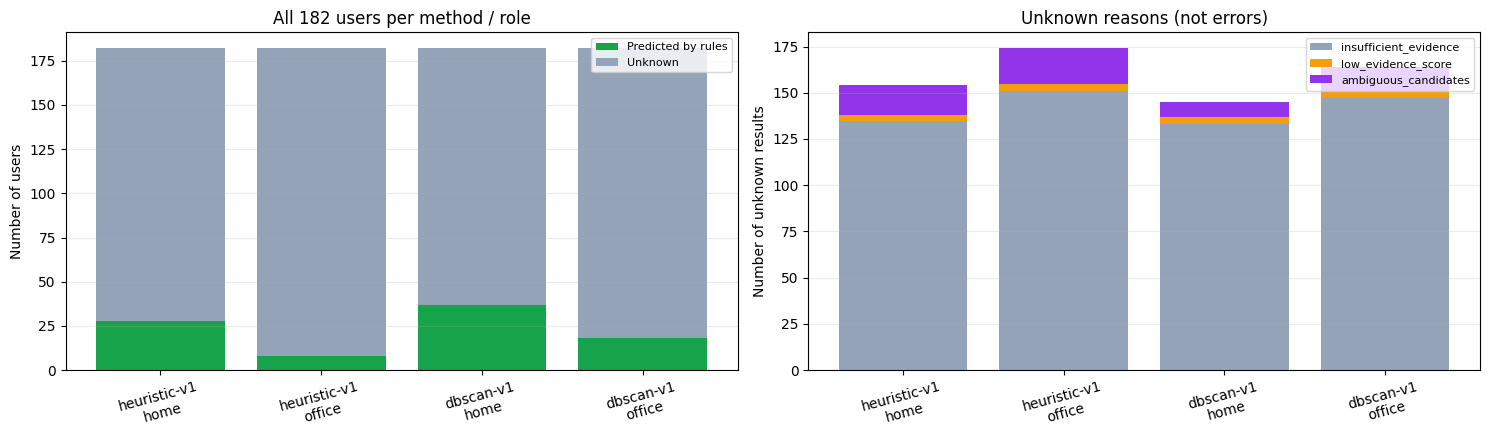

,method,role,users,predicted,unknown,unknown_no_stays,unknown_no_cluster
0,heuristic-v1,home,182,28,154,31,0
1,heuristic-v1,office,182,8,174,31,0
2,dbscan-v1,home,182,37,145,31,48
3,dbscan-v1,office,182,18,164,31,48


In [9]:
summary_rows = []
for method in METHODS:
    for role in ['home', 'office']:
        frame = decisions.loc[decisions['method'].eq(method) & decisions['role'].eq(role)]
        summary_rows.append(dict(method=method, role=role, users=len(frame),
                                predicted=int(frame['status'].eq('predicted').sum()),
                                unknown=int(frame['status'].eq('unknown').sum()),
                                unknown_no_stays=int((frame['status'].eq('unknown') & frame['input_context'].eq('no_stays')).sum()),
                                unknown_no_cluster=int((frame['status'].eq('unknown') & frame['input_context'].eq('no_non_noise_cluster')).sum())))
summary = pd.DataFrame(summary_rows)
assert summary['users'].eq(len(users)).all()
assert summary['predicted'].add(summary['unknown']).eq(len(users)).all()
labels = [f"{row.method}\n{row.role}" for row in summary.itertuples()]
x = np.arange(len(summary))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].bar(x, summary['predicted'], label='Predicted by rules', color='#16a34a')
axes[0].bar(x, summary['unknown'], bottom=summary['predicted'], label='Unknown', color='#94a3b8')
axes[0].set(ylabel='Number of users', title=f'All {len(users)} users per method / role')
bottom = np.zeros(len(summary))
for reason, color in [('insufficient_evidence', '#94a3b8'), ('low_evidence_score', '#f59e0b'), ('ambiguous_candidates', '#9333ea')]:
    values = [int(((decisions['method'] == row.method) & (decisions['role'] == row.role)
                   & decisions['status'].eq('unknown') & decisions['reason'].eq(reason)).sum())
              for row in summary.itertuples()]
    axes[1].bar(x, values, bottom=bottom, label=reason, color=color)
    bottom += values
axes[1].set(ylabel='Number of unknown results', title='Unknown reasons (not errors)')
for ax in axes:
    ax.set_xticks(x, labels, rotation=15)
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=.25)
fig.tight_layout()
fig.savefig(OUT / '01_decision_status.png', dpi=150)
plt.show()
display(summary)

## 7. Đối chiếu bằng chứng ban đêm và giờ làm việc

Mỗi chấm là **một cluster**, không phải một GPS point. Dùng mọi cluster của mỗi phương pháp.
**X:** số giờ dừng ban đêm; **Y:** số giờ dừng 9h–18h ngày thường. Trục nén theo log sau 1 phút, vẫn hiển thị 0. Các đường đứt ở 1 giờ là ngưỡng dwell tối thiểu, chưa đủ để gán nhãn vì còn ngày/tuần/điểm và cạnh tranh.

Màu xanh = Home đã chọn, cam = Office, tím = cùng Home+Office, xám = cluster khác. Không vẽ noise ở đây vì noise không phải cluster; xem `user_diagnostics.csv` để biết phần bằng chứng nằm ngoài các cluster.

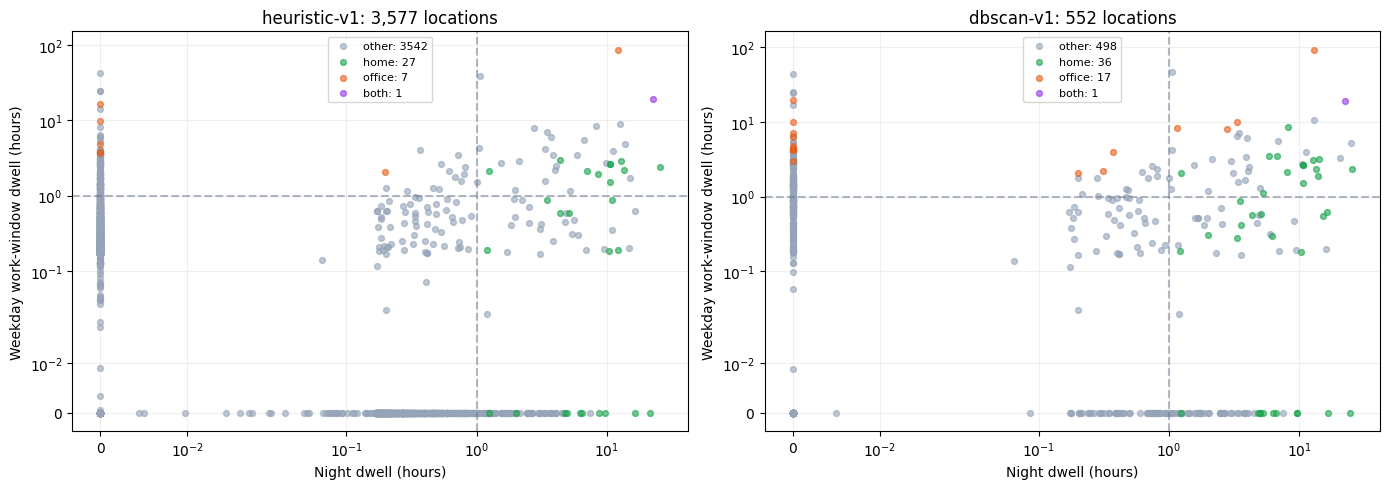

In [10]:
fig, axes = plt.subplots(1, len(METHODS), figsize=(14, 5), squeeze=False)
selected_keys = {(r.method, r.user_id, int(r.cluster_id)): set()
                 for r in decisions.loc[decisions['status'].eq('predicted')].itertuples()}
for row in decisions.loc[decisions['status'].eq('predicted')].itertuples():
    selected_keys[(row.method, row.user_id, int(row.cluster_id))].add(row.role)
for ax, method in zip(axes[0], METHODS):
    frame = location_features.loc[location_features['method'].eq(method)]
    categories = {'home': [], 'office': [], 'both': [], 'other': []}
    for row in frame.itertuples():
        roles = selected_keys.get((method, row.user_id, int(row.cluster_id)), set())
        category = 'both' if len(roles) == 2 else next(iter(roles)) if roles else 'other'
        categories[category].append((row.night_dwell_minutes / 60, row.weekday_daytime_dwell_minutes / 60))
    for category, color in [('other', '#94a3b8'), ('home', '#16a34a'), ('office', '#e85b17'), ('both', '#9333ea')]:
        values = np.asarray(categories[category], dtype=float).reshape(-1, 2)
        ax.scatter(values[:, 0], values[:, 1], s=18, alpha=.6, color=color, label=f'{category}: {len(values)}')
    ax.set(xscale='symlog', yscale='symlog', xlabel='Night dwell (hours)', ylabel='Weekday work-window dwell (hours)', title=f'{method}: {len(frame):,} locations')
    ax.set_xscale('symlog', linthresh=1/60)
    ax.set_yscale('symlog', linthresh=1/60)
    ax.axvline(CONFIG.min_role_dwell_minutes / 60, color='#64748b', linestyle='--', alpha=.5)
    ax.axhline(CONFIG.min_role_dwell_minutes / 60, color='#64748b', linestyle='--', alpha=.5)
    ax.legend(fontsize=8)
    ax.grid(alpha=.2)
fig.tight_layout()
fig.savefig(OUT / '02_temporal_evidence.png', dpi=150)
plt.show()

## 8. Đọc chi tiết một user sau khi đã tính toàn dataset

Đổi `REVIEW_USER` để xem quyết định và bảng điểm của bất kỳ user nào. Đây chỉ là **lọc bảng để đọc**, không giới hạn phạm vi tính toán. Bảng có mọi ứng viên của user đó, kể cả ứng viên không đủ điều kiện hoặc không được chọn.

Các cột `weighted_*` cộng lại thành điểm. `eligibility_failures` ghi thiếu ngày/phút/tuần; `reason` ở bảng quyết định còn xét điểm, share và chênh lệch với đối thủ.

In [11]:
REVIEW_USER = str(users.index[0])
assert REVIEW_USER in users.index, 'User không tồn tại trong dataset.'
display(decisions.loc[decisions['user_id'].eq(REVIEW_USER)])
display(candidate_scores.loc[candidate_scores['user_id'].eq(REVIEW_USER), [
    'method', 'role', 'rank', 'cluster_id', 'selected', 'eligible', 'eligibility_failures',
    'role_visit_days', 'role_dwell_minutes', 'evidence_score', 'relative_share', 'share_including_noise',
    *['weighted_' + k for k in EVIDENCE_WEIGHTS]]])
display(user_diagnostics.loc[user_diagnostics['user_id'].eq(REVIEW_USER)])
display(pois.loc[pois['user_id'].eq(REVIEW_USER)])

,method,user_id,role,status,reason,input_context,cluster_id,latitude,longitude,evidence_score,role_dwell_minutes,role_visit_days,top_ranked_cluster_id,top_ranked_score
0,heuristic-v1,000,home,predicted,sufficient_heuristic_evidence,has_clusters,4,40.009695,116.315136,0.509805,261.283333,3.0,4,0.509805
1,heuristic-v1,000,office,unknown,insufficient_evidence,has_clusters,<NA>,NaN,NaN,NaN,NaN,NaN,6,0.437009
364,dbscan-v1,000,home,predicted,sufficient_heuristic_evidence,has_clusters,1,40.009695,116.315136,0.521813,261.283333,3.0,1,0.521813
365,dbscan-v1,000,office,unknown,insufficient_evidence,has_clusters,<NA>,NaN,NaN,NaN,NaN,NaN,2,0.448025


,method,role,rank,cluster_id,selected,eligible,eligibility_failures,role_visit_days,role_dwell_minutes,evidence_score,relative_share,share_including_noise,weighted_recurrence,weighted_duration,weighted_temporal_consistency,weighted_coverage,weighted_relative_strength
0,heuristic-v1,home,1,4,True,True,,3,261.283333,0.509805,0.619816,0.619816,0.18,0.108868,0.008955,0.15,0.061982
1,heuristic-v1,home,2,12,False,False,too_few_role_days;too_little_role_dwell,2,20.350000,0.289277,0.048274,0.048274,0.12,0.008479,0.005970,0.15,0.004827
2,heuristic-v1,home,3,7,False,False,too_few_role_days;too_little_role_dwell,1,46.583333,0.243445,0.110505,0.110505,0.06,0.019410,0.002985,0.15,0.011050
3,heuristic-v1,home,4,8,False,False,too_few_role_days;too_little_role_dwell,1,24.916667,0.229278,0.059107,0.059107,0.06,0.010382,0.002985,0.15,0.005911
4,heuristic-v1,home,5,24,False,False,too_few_role_days;too_little_role_dwell,1,20.166667,0.226172,0.047839,0.047839,0.06,0.008403,0.002985,0.15,0.004784
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7167,dbscan-v1,office,5,8,False,False,too_few_role_days;too_few_work_weeks,1,62.466667,0.263173,0.247638,0.132270,0.06,0.026028,0.002381,0.15,0.024764
7168,dbscan-v1,office,6,3,False,False,too_few_role_days;too_little_role_dwell;too_fe...,1,28.500000,0.235554,0.112983,0.060347,0.06,0.011875,0.002381,0.15,0.011298
7169,dbscan-v1,office,7,4,False,False,too_few_role_days;too_little_role_dwell;too_fe...,1,10.333333,0.220783,0.040965,0.021880,0.06,0.004306,0.002381,0.15,0.004096
7170,dbscan-v1,office,8,6,False,False,too_few_role_days;too_little_role_dwell;too_fe...,0,0.000000,0.150000,0.000000,0.000000,0.00,0.000000,0.000000,0.15,0.000000


,method,user_id,stay_count,noise_stays,noise_fraction,locations,noise_night_minutes,noise_work_minutes,all_stay_night_minutes,all_stay_work_minutes
0,heuristic-v1,000,120,0,0.000000,52,0.000000,0.000000,421.55,472.266667
182,dbscan-v1,000,120,53,0.441667,9,68.416667,220.016667,421.55,472.266667


,method,user_id,cluster_id,latitude,longitude,unique_visit_days,visit_count,total_dwell_minutes
0,heuristic-v1,000,7,40.007919,116.319459,7,8,160.750000
1,heuristic-v1,000,6,40.010295,116.322192,5,5,81.666667
2,heuristic-v1,000,12,40.000755,116.327549,4,8,127.133333
3,heuristic-v1,000,8,40.079428,116.586697,3,4,66.250000
4,heuristic-v1,000,1,40.011513,116.296895,3,3,54.500000
265,dbscan-v1,000,3,40.007919,116.319459,7,8,160.750000
266,dbscan-v1,000,2,40.010295,116.322192,5,5,81.666667
267,dbscan-v1,000,5,40.000755,116.327549,4,8,127.133333
268,dbscan-v1,000,4,40.079428,116.586697,3,4,66.250000
269,dbscan-v1,000,0,40.011513,116.296895,3,3,54.500000


## 9. Map nhãn Home / Office / POI

Dùng toàn bộ assignments/locations cũ; chỉ thêm nhãn đã được chọn, không thay clusters. **H** = Home, **O** = Office, **H+O** = cùng một cluster, **P** = POI. User chưa đủ bằng chứng sẽ hiện `unknown`, không đặt marker tại tọa độ giả.

Map có bộ chọn mọi user/toàn bộ và hai phương pháp cạnh nhau. Nút **Zoom nơi thường ghé** giúp nhìn gần hơn. Màu cluster không ghép nhãn giữa hai phương pháp; marker H/O/P là kết luận theo rule đang xét.

Mở file `artifacts/inference/03_role_map.html` bằng Chrome/Edge để xem nền đường phố. Cần internet. Nếu iframe trong notebook có nền xám, mở file HTML riêng như NB04; không cần chạy lại thuật toán.

In [12]:
from html import escape
from IPython.display import IFrame
from geolife_inference.maps import write_location_map

label_rows = decisions.loc[decisions['status'].eq('predicted'),
                           ['method', 'user_id', 'cluster_id', 'role']].to_dict('records')
label_rows += [dict(method=r.method, user_id=r.user_id, cluster_id=int(r.cluster_id), role='poi')
               for r in pois.itertuples()]
role_labels = pd.DataFrame(label_rows, columns=['method', 'user_id', 'cluster_id', 'role'])
location_keys = set(map(tuple, saved_locations[['method', 'user_id', 'cluster_id']].to_numpy()))
for row in role_labels.itertuples():
    assert (row.method, row.user_id, int(row.cluster_id)) in location_keys
assert input_fingerprints() == INPUT_FINGERPRINTS, 'Input đã đổi; chạy lại từ phần 1.'
assert CONFIG.to_dict() == run_audit['config'], 'CONFIG đã đổi; chạy lại từ phần 3.'
MAP_PATH = write_location_map(assignments, saved_locations, users.index,
                              OUT / '03_role_map.html', CONFIG, role_labels=role_labels)
print('Mở bằng trình duyệt:', MAP_PATH)
display(IFrame('about:blank', width='100%', height=850,
               extras=['title="GeoLife role map"', 'style="border:0"',
                       'srcdoc="' + escape(MAP_PATH.read_text(encoding='utf-8'), quote=True) + '"']))

Mở bằng trình duyệt: e:\QUY\Geolife-Trajectories\artifacts\inference\03_role_map.html


## 10. Lưu baseline và xác nhận đủ phạm vi

Kết quả gồm mọi user của cả hai phương pháp; unknown là một kết quả hợp lệ. CSV dùng ID dạng chuỗi để giữ số 0 ở đầu. `predictions.json` giữ candidate/alternatives/POIs, cấu hình, fingerprints và cách hiểu score.

Chỉ dùng kết quả khi audit ghi `completed` và input chưa đổi. Đổi CONFIG thì chạy lại từ phần 3; cache tự khớp khung giờ, không dùng nhầm coverage cũ. Kết quả cũ còn trên ổ đĩa không đại diện cho một lượt mới đang lỗi.

In [13]:
try:
    assert input_fingerprints() == INPUT_FINGERPRINTS, 'Input đã đổi; chạy lại từ phần 1.'
    assert CONFIG.to_dict() == run_audit['config'], 'CONFIG đã đổi; chạy lại từ phần 3.'
    for name, table, index in [('decisions.csv', decisions, False), ('candidate_scores.csv', candidate_scores, False),
                               ('location_features.csv', location_features, False), ('pois.csv', pois, False),
                               ('user_diagnostics.csv', user_diagnostics, False), ('summary.csv', summary, False)]:
        partial = OUT / (name + '.partial')
        table.to_csv(partial, index=index)
        partial.replace(OUT / name)
    write_json(OUT / 'predictions.json', {
        'scope': 'full_dataset', 'config': CONFIG.to_dict(), 'input_fingerprints': INPUT_FINGERPRINTS,
        'score_semantics': 'Uncalibrated heuristic evidence score; not a probability.',
        'coverage_policy': 'GPS pairs within trajectory/segment, union across files; includes movement.',
        'results': predictions})
    run_audit.update(status='completed', processed_users=len(users), methods=METHODS,
        processed_points=int(coverage['processed_points'].sum()),
        processed_trajectories=int(coverage['processed_trajectories'].sum()),
        input_stays=len(assignments), input_locations=len(saved_locations),
        decision_rows=len(decisions), candidate_score_rows=len(candidate_scores), poi_rows=len(pois),
        summary=summary.to_dict('records'),
        limitations=['uncalibrated_scores', 'no_semantic_ground_truth', 'fixed_timezone_and_windows',
                     'relative_share_excludes_noise', 'extended_clusters_retained'])
    write_audit()
except Exception as error:
    run_audit.update(status='failed', error=str(error))
    write_audit()
    raise
print('Status:', run_audit['status'], '| Kết quả:', OUT)

Status: completed | Kết quả: e:\QUY\Geolife-Trajectories\artifacts\inference


## 11. Thử độ nhạy rule suy luận — tùy chọn

Bật `RUN_SENSITIVITY = True` để đổi một ngưỡng mỗi lần: tối thiểu 5 ngày, 120 phút, score 0,6 hoặc share 0,6. Mỗi cấu hình xét **toàn bộ users/clusters của cả hai phương pháp**, giữ nguyên khung giờ, coverage và clustering.

Không cần đọc lại 24 triệu GPS points, vì các cấu hình này chỉ đổi điều kiện quyết định. Không ghi đè baseline hoặc map. So tỷ lệ predicted/unknown và số user đổi nhãn/cluster; giảm unknown không tự nghĩa là tốt hơn. Đổi khung giờ cần tính lại coverage/features, không dùng phần này để giả lập bằng cache cũ.

In [ ]:
RUN_SENSITIVITY = True  # Nếu muốn chạy sensitivity, đổi thành True; nếu không, giữ False.
if RUN_SENSITIVITY:
    assert run_audit['status'] == 'completed' and CONFIG.to_dict() == run_audit['config']
    assert input_fingerprints() == INPUT_FINGERPRINTS
    scenarios = {'min_days_5': replace(CONFIG, min_role_days=5),
                 'min_dwell_120min': replace(CONFIG, min_role_dwell_minutes=120),
                 'score_0.6': replace(CONFIG, min_evidence_score=.6),
                 'share_0.6': replace(CONFIG, min_candidate_share=.6)}
    baseline = decisions.set_index(['method', 'user_id', 'role'])
    rows = []
    for name, config in {'baseline': CONFIG, **scenarios}.items():
        alternative, _, alternate_pois, _ = infer_all(config)
        assert len(alternative) == len(decisions)
        alt = alternative.set_index(['method', 'user_id', 'role']).reindex(baseline.index)
        changed = alt['status'].ne(baseline['status']) | alt['cluster_id'].fillna(-1).ne(baseline['cluster_id'].fillna(-1))
        for method in METHODS:
            for role in ['home', 'office']:
                frame = alternative.loc[alternative['method'].eq(method) & alternative['role'].eq(role)]
                rows.append(dict(scenario=name, method=method, role=role, users=len(frame),
                    predicted=int(frame['status'].eq('predicted').sum()), unknown=int(frame['status'].eq('unknown').sum()),
                    changed_vs_baseline=int(changed.loc[(method, slice(None), role)].sum()),
                    poi_count=int(alternate_pois['method'].eq(method).sum()),
                    min_role_days=config.min_role_days, min_role_dwell_minutes=config.min_role_dwell_minutes,
                    min_evidence_score=config.min_evidence_score, min_candidate_share=config.min_candidate_share))
    assert input_fingerprints() == INPUT_FINGERPRINTS, 'Input đổi trong lúc chạy sensitivity.'
    sensitivity = pd.DataFrame(rows)
    partial = OUT / 'sensitivity.csv.partial'
    sensitivity.to_csv(partial, index=False)
    partial.replace(OUT / 'sensitivity.csv')
    write_json(OUT / 'sensitivity_audit.json', {'status': 'completed', 'scope': 'full_dataset',
        'input_fingerprints': INPUT_FINGERPRINTS, 'baseline_config': CONFIG.to_dict(),
        'scenarios': {k: c.to_dict() for k, c in scenarios.items()}, 'rows': len(sensitivity)})
    display(sensitivity)
else:
    print('Chưa chạy sensitivity. Baseline vẫn xét đủ mọi user, gồm cả unknown.')

Chưa chạy sensitivity. Baseline vẫn xét đủ mọi user, gồm cả unknown.


## Kết quả và giới hạn của phase 5

Sau khi chạy xong, `artifacts/inference/` có bảng coverage/cache audit, temporal features, mọi điểm ứng viên,
quyết định Home/Office, POIs, diagnostics, summary, predictions JSON, hai chart và một map HTML.
Sensitivity có bảng/audit riêng khi được bật. Chỉ giữ một notebook làm việc.

Có thể xem được **nơi nào được chọn, dựa vào thời gian/ngày/tuần nào, điểm gồm những phần gì, đối thủ nào còn gần và vì sao unknown**. Không xác nhận được danh tính thực của địa điểm chỉ từ GPS. Noise nhiều, cluster bị nối quá rộng, thiếu GPS trong nhà, du lịch và ca làm khác giờ đều có thể gây sai.

Đọc kết quả baseline/map/sensitivity trước khi chốt rule. Chưa có nhãn để công bố accuracy/F1, chưa làm HTTP endpoints hoặc cloud. Thiết kế API chỉ được chuyển sang triển khai sau khi người dùng xác nhận mentor đã duyệt.